<a href="https://colab.research.google.com/github/Max-Acevedo940/csc451-project/blob/main/notebooks/02_train_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Small MLP Classififer

In [56]:
import pandas as pd
import numpy as np

data_url = "https://raw.githubusercontent.com/CharlizeCo/house_prices_csc481_project/refs/heads/main/CSC%20451%20Dataset%20-%20Sheet1.csv"
speech_df = pd.read_csv(data_url)
speech_df.head()

,Id,Post,Class (0-5),Max Acevedo,Charlize Corriette,La'Shawn Louder,Post Length (Characters),Unnamed: 7,Unnamed: 8
0,1,Even 2 month old baby girl is not safe in Indi...,NaN,2.0,1.0,1.0,68,NaN,Link 1
1,2,these bhagwa terrorists can't digest their mea...,NaN,5.0,5.0,5.0,196,NaN,https://github.com/codogogo/xhate/tree/main
2,3,What kind of media is this!!first they make he...,NaN,1.0,1.0,1.0,268,NaN,https://github.com/codogogo/xhate/blob/main/te...
3,4,Compensation to the States will be payable eve...,NaN,0.0,0.0,0.0,61,NaN,NaN
4,5,"Nifty below 8550 , indicates a down move maybe...",NaN,0.0,0.0,0.0,53,NaN,Link 2


In [57]:
sample = speech_df.head(200).copy()
score_col = ["Max Acevedo","Charlize Corriette","La'Shawn Louder"]

row_mean = sample[score_col].mean(axis=1)
# fill only the NaNs with that row mean
sample[score_col] = sample[score_col].apply(lambda col: col.fillna(row_mean))

sample["avg_score"] = sample[score_col].mean(axis=1)
print(sample["avg_score"].head(10))

0    1.333333
1    5.000000
2    1.000000
3    0.000000
4    0.000000
5    0.000000
6    0.000000
7    0.000000
8    1.000000
9    0.000000
Name: avg_score, dtype: float64


In [58]:
sample["avg_score"].dtype

dtype('float64')

In [59]:
sample["Post Length (Characters)"].dtype

dtype('int64')

In [60]:
sample["label"] = sample["avg_score"].round().astype("Int64")

In [61]:
from sklearn.model_selection import train_test_split, learning_curve

X = sample['Post']
y = sample['label']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

In [64]:
from sklearn.neural_network import MLPClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MaxAbsScaler
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(
    TfidfVectorizer(max_features=500, ngram_range=(1,2)),
    MaxAbsScaler(),
    MLPClassifier(hidden_layer_sizes=(16,), max_iter=500,
                  early_stopping=True, validation_fraction=0.2,
                  random_state=42),
)

In [65]:
pipe.fit(X_train, y_train)
print("Accuracy:", pipe.score(X_test, y_test))

Accuracy: 0.8666666666666667


Baseline

In [66]:
vals, counts = np.unique(y_train, return_counts=True)
majority_frac = counts.max() / len(y_train)

In [67]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(baseline.score(X_test, y_test))

0.8666666666666667


Learning Curve

In [68]:
train_sizes, train_scores, val_scores = learning_curve(
    pipe, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    shuffle=True,
    random_state=42,
)

train_mean, train_std = train_scores.mean(1), train_scores.std(1)
val_mean, val_std = val_scores.mean(1), val_scores.std(1)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


Plot

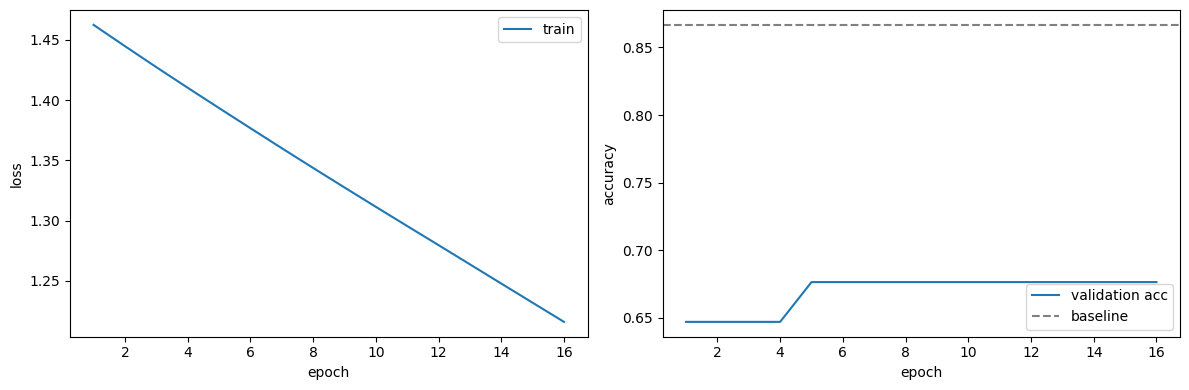

In [69]:
mlp = pipe.named_steps["mlpclassifier"]
epochs = range(1, len(mlp.loss_curve_) + 1)
baseline_val = baseline.score(X_test, y_test)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(epochs, mlp.loss_curve_, label="train")
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()

ax2.plot(epochs, mlp.validation_scores_, label="validation acc")
ax2.axhline(baseline_val, color="gray", ls="--", label="baseline")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend()
plt.tight_layout()
plt.show()

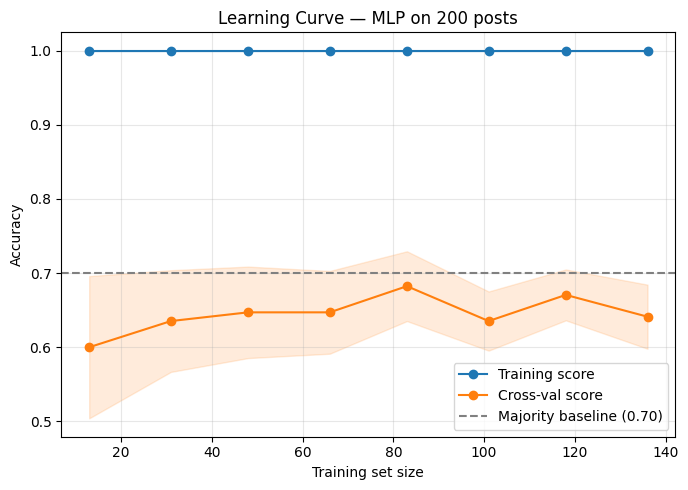

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15, color="tab:blue")
plt.fill_between(train_sizes, val_mean-val_std,     val_mean+val_std,     alpha=0.15, color="tab:orange")
plt.plot(train_sizes, train_mean, "o-", color="tab:blue",   label="Training score")
plt.plot(train_sizes, val_mean,   "o-", color="tab:orange", label="Cross-val score")
plt.axhline(majority_frac, ls="--", color="gray",
            label=f"Majority baseline ({majority_frac:.2f})")
plt.xlabel("Training set size"); plt.ylabel("Accuracy")
plt.title("Learning Curve — MLP on 200 posts")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.show()